# Lattice construction

In [1]:
lattice_name   = 'v01_02_01_01'
description    = 'Longitudinal gradient bend lattice starting from v01_01_03_01.'
finalized_date = '261104'

In [2]:
# Standard imports
import numpy as np
import scipy
import matplotlib.pyplot as plt

import pickle
import os
from copy import deepcopy

import at

import utils as u

from importlib import reload

reload(u.at);
reload(u.plot);

## Load ring

In [3]:
with open('candidates/v01_01_03_01/ring.pkl', 'rb') as file:
    ring0 = pickle.load(file)

# Make sure quads share reference
for fam in ['Q1_v1', 'Q2_v1', 'Q3_v1']:
    e = ring0[fam][0]
    for i in ring0.uint32_refpts(fam):
        ring0[i] = e

## Increase number of slices

In [4]:
""" Create slices """
def make_slices(elements, n_slices, length):
    # Include all original slices, including fringes, when conserving integrated strengths.
    elements = list(elements)

    # Sum bending angles and integrated multipole strengths from the original slices.
    bending_angle = sum(getattr(el, "BendingAngle", 0.0) for el in elements)

    K = {}
    for el in elements:
        for order, value in enumerate(el.PolynomB[1:], start=1):
            K[order] = K.get(order, 0.0) + value * el.Length

    # Use the first element as a template for the new slices.
    template = elements[0]
    new_slices = []

    for i in range(n_slices):
        element = deepcopy(template)
        el = at.Dipole(
            template.FamName,
            length / n_slices,
            BendingAngle=bending_angle / n_slices,
            PolynomA=np.zeros(4),
            PolynomB=np.zeros(4),
            MaxOrder=template.MaxOrder,
            NumIntSteps=template.NumIntSteps,
            PassMethod=template.PassMethod,
        )
        el.EAperatures = deepcopy(template.EApertures)

        # Exactly four elements in each polynomial array.
        el.PolynomA = np.zeros(4)
        el.PolynomB = np.zeros(4)

        for order, value in K.items():
            if order < 4:
                el.PolynomB[order] = value / length

        new_slices.append(el)

    return at.Lattice(new_slices, energy=ring0.energy)

n_D1 = 10 # Number of slices
n_D2 = 10 # Number of slices (per half)
n_R1 = 3  # Number of slices

# Get one segment of each type
D1_0 = ring0['D1_v1'][0:24//2] 
D2_0 = ring0['D2_v1'][0:80//10]
R1_0 = ring0['R1_v1'][0]  

# Lengths excluding fringe fields
L_D1 = u.at.get_length(D1_0[1:-2])
L_D2 = u.at.get_length(D2_0[2:])
L_R1 = u.at.get_length(R1_0)

# Create new slices
D1_new = make_slices(D1_0, n_D1, L_D1)
D2_new = make_slices(D2_0, n_D2, L_D2)
R1_new = make_slices([R1_0], n_R1, L_R1)

# Mirror D2 slices
D2_new.extend(D2_new[::-1])

""" Insert slices """
ring = u.at.replace_family(ring0, 'D1_v1', replacement=D1_new, alternate=True)
# Correct D1 placement (Different number of fringe slices on each side)
assert len(ring['strx075']) == 4

strx100 = at.Drift('strx100', 0.1)
strx050 = at.Drift('strx050', 0.05)
for i, index in enumerate(ring.uint32_refpts('strx075')):
    ring[index] = strx050 if i in [0, 3] else strx100

ring = u.at.replace_family(ring, 'D2_v1', replacement=D2_new)
ring = u.at.replace_family(ring, 'R1_v1', replacement=R1_new, alternate=True)

print(u.at.get_length(ring0))
print(u.at.get_length(ring))

26.404307767988193
26.404307767988268


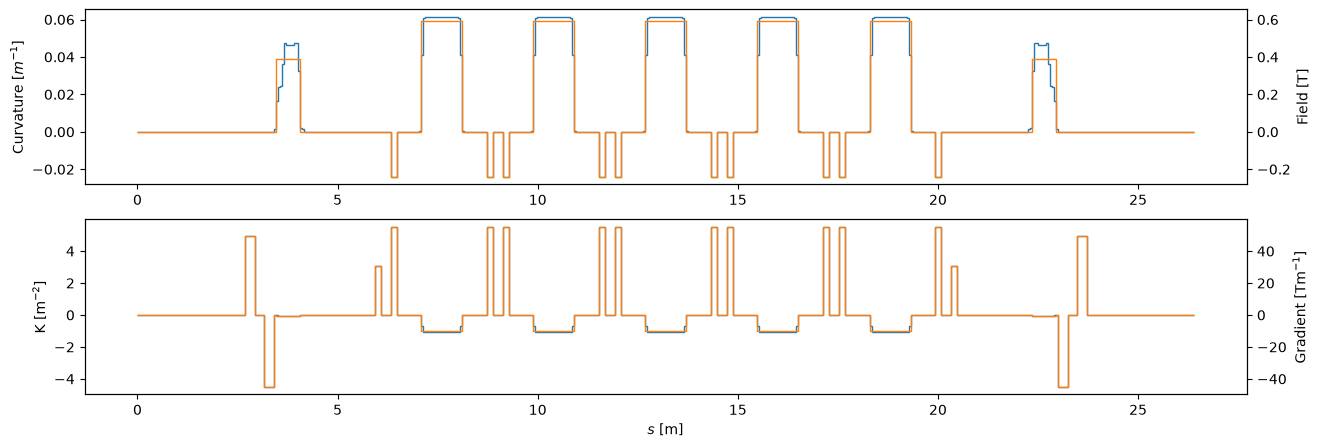

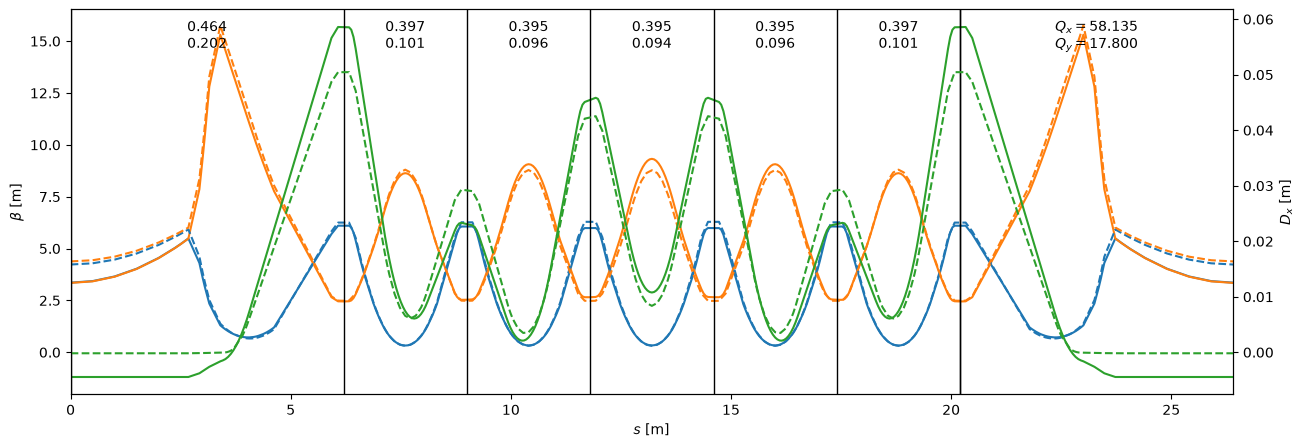

In [6]:
fig, axs = plt.subplots(2, 1, figsize=(15, 5))
u.plot.plot_magnet(ring0, axs)
u.plot.plot_magnet(ring, axs)
plt.show()

fig, ax = plt.subplots(1, 1, figsize=(15, 5))
u.plot.linear(ring, ax=ax)
plt.show()

## Free-form optimization

In [35]:
from IPython.display import clear_output
def callback(intermediate_result):
    clear_output(wait=True)
    print('Running...')
    print(intermediate_result)

def set_x(ring, x, index_rho, index_K):
    # Unpack
    L = x[0]
    rho_inv = x[1:len(index_rho)+1]
    K = x[len(index_rho)+1:]

    assert len(rho_inv) == len(index_rho), f"rho_inv and index_rho should have the same lengths but have lengths {len(rho_inv)} and {len(index_rho)}"
    assert len(K) == len(index_K), f"rho_inv and index_rho should have the same lengths but have lengths {len(K)} and {len(index_K)}"

    for e in ring['strx203']: e.Length = L
    for i, e in enumerate(ring[index_rho]): e.BendingAngle = e.Length * rho_inv[i]
    for i, e in enumerate(ring[index_K]): e.K = K[i]

def get_x(ring, index_rho, index_K):
    L = ring['strx203'][0].Length

    rho_inv = [ring[i].BendingAngle/ring[i].Length for i in index_rho]
    K       = [ring[i].K                           for i in index_K]

    return np.array([L] + rho_inv + K)

def loss(x, ring, index_rho, index_K):
    # Set fields
    set_x(ring, x, index_rho, index_K)

    try:
        emittance = 1e12 * ring.radiation_parameters().emittances[0]
    except Exception as e:
        emittance = 1000

    return emittance

def exact_constraints(x, ring, index_rho, index_K):
    # Set fields
    set_x(ring, x, index_rho, index_K)

    """ Geometric constraints """
    geometry = ring.get_geometry(at.End)[0]
    geometry0 = ring0.get_geometry(at.End)[0]

    x_end = geometry.x[0] - geometry0.x[0]
    theta_UC = geometry.angle[0] - geometry0.angle[0]

    """ Optics """
    elemdata = at.linopt4(ring, at.All)[2]

    # Dispersion
    D0, Dp0 = elemdata.dispersion[0, 0:2]

    return x_end, theta_UC, D0, Dp0

def phase_constraints(x, ring, index_rho, index_K):
    tune = np.array([58.399, 17.168])
    UC_tune = np.array([0.4, 0.1])

    # Set fields
    set_x(ring, x, index_rho, index_K)

    """ Optics """
    elemdata = at.linopt4(ring, at.All)[2]

    # Unit cell phase advance
    index_UC = ring.get_uint32_index('UCborder')
    phase_diff = (np.diff(elemdata.mu[index_UC], axis=0)/(2*np.pi) - UC_tune).flatten()

    # Full tunes
    tune_diff = 20*elemdata.mu[-1]/(2*np.pi) - tune

    return 1e-3 + np.hstack([-phase_diff, phase_diff, -tune_diff, tune_diff]) # Within 1-e3 

index_rho = np.hstack([ring.uint32_refpts('D1_v1')[:n_D1],
                       ring.uint32_refpts('R1_v1')[:n_R1],
                       ring.uint32_refpts('D2_v1')[:n_D2]])

index_K = np.hstack([ring.uint32_refpts('Q1_v1')[0],
                     ring.uint32_refpts('Q2_v1')[0],
                     ring.uint32_refpts('D1_v1')[:n_D1],
                     ring.uint32_refpts('Q3_v1')[0],
                     ring.uint32_refpts('R1_v1')[:n_R1],
                     ring.uint32_refpts('D2_v1')[:n_D2]])

In [36]:
bounds = (1 + len(index_rho) + len(index_K))*[(None, None)]
for i, index in enumerate(np.hstack([index_rho]), 1):
    if 'D1' in ring[index].FamName: 
        bounds[i] = (0, 0.07)
    if 'D2' in ring[index].FamName: 
        bounds[i] = (0, 0.07) 
    if 'R1' in ring[index].FamName: 
        bounds[i] = (-0.025, 0)

for i, index in enumerate(np.hstack([index_K]), len(index_rho)+1):
    if 'D1' in ring[index].FamName: 
        bounds[i] = (-1.2, 0)
    if 'D2' in ring[index].FamName: 
        bounds[i] = (-1.2, 0)

    if 'R1' in ring[index].FamName: 
        bounds[i] = (-6, 6)
    if 'Q1' in ring[index].FamName: 
        bounds[i] = (-6, 6)
    if 'Q2' in ring[index].FamName: 
        bounds[i] = (-6, 6)
    if 'Q3' in ring[index].FamName: 
        bounds[i] = (-6, 6)

ring_opt = deepcopy(ring)
result = scipy.optimize.minimize(
    loss,
    get_x(ring, index_rho, index_K),
    args=(ring_opt, index_rho, index_K),
    constraints=[
        {'type':   'eq', 'fun': exact_constraints, 'args': (ring_opt, index_rho, index_K)},
        {'type': 'ineq', 'fun': phase_constraints, 'args': (ring_opt, index_rho, index_K)},
    ],
    bounds=bounds,
    callback=callback,
)
result

Running...
 fun: 61.66891126831606
   x: [ 2.041e-01  2.207e-10 ... -8.519e-01 -2.964e-02]


     message: Optimization terminated successfully
     success: True
      status: 0
         fun: 52.992123770035484
           x: [ 2.040e-01  2.224e-12 ... -8.313e-01 -4.868e-02]
         nit: 55
         jac: [ 4.057e+01  2.613e+02 ...  8.085e-01  8.315e-01]
        nfev: 2936
        njev: 54
 multipliers: [ 2.946e+00 -6.692e+02 ...  0.000e+00  0.000e+00]

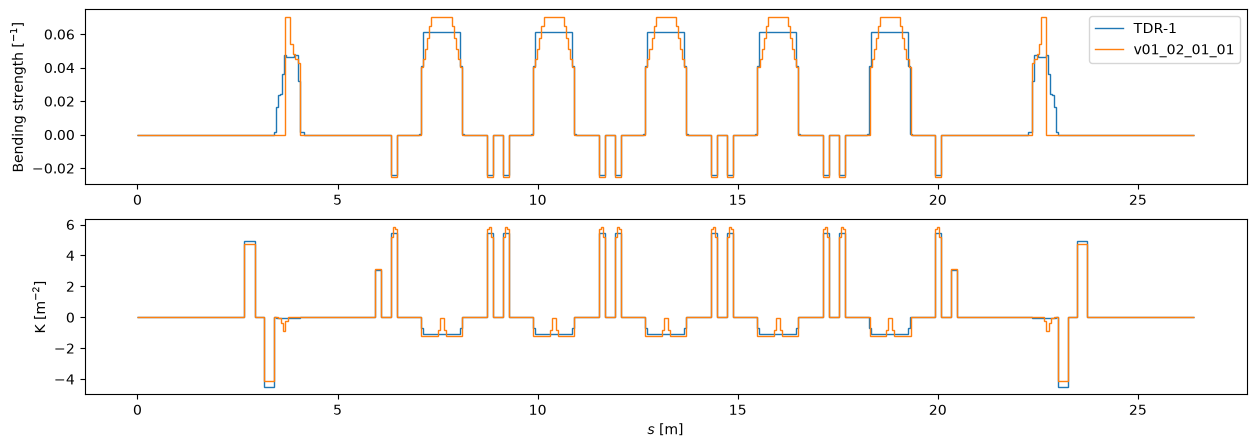

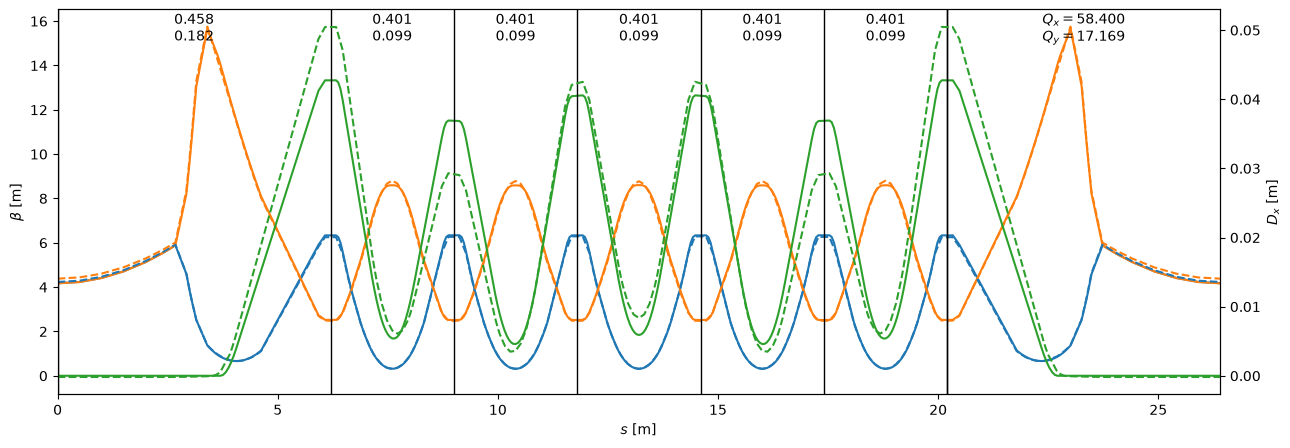

In [41]:
fig, axs = plt.subplots(2, 1, figsize=(15, 5))
u.plot.plot_magnet(ring0, axs)
u.plot.plot_magnet(ring_opt, axs)
axs[0].legend(['TDR-1', lattice_name])

fig, ax = plt.subplots(1, 1, figsize=(15, 5))
u.plot.linear(ring_opt, ax=ax)
plt.show()

In [ ]:
def get_cro_separation(ring):
    """ Separation between synchrotron light and the beam at the crotch absorber. """
    s_cro = np.mean([ring.get_s_pos('GE')[0], ring.get_s_pos('GS')[1]]) # For now
    
    return -np.interp(s_cro, ring.get_s_pos(), ring.get_geometry()[0].y)

cro_separation = get_cro_separation(ring_opt)
print(f'Separation at crotch absorber: {1e3*cro_separation:.1f} mm')

Separation at crotch absorber: 28.2 mm


## Save lattice

In [ ]:
try:
    os.mkdir(f'candidates/{lattice_name}')
except FileExistsError:
    pass
    
with open(f'candidates/{lattice_name}/ring.pkl', 'wb') as file:
    pickle.dump(ring_opt, file)

at.save_mat(ring_opt, f'candidates/{lattice_name}/achro.mat')